## Sliding Window BP with VAR Forecasting

This notebook evaluates sliding-window backpropagation of the received scintillation field. The full noncausal sliding-window result uses observed samples on both sides of the target sample. The latency-limited cases use observed samples through `k + L` and fill the remaining future half-window with a VAR forecast fitted directly to the real and imaginary parts of the received field.


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft, ifft
from scipy.io import loadmat
from scipy.signal import get_window
from statsmodels.tsa.vector_ar.var_model import VAR

plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 16,
        "axes.labelsize": 13,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 9,
        "legend.title_fontsize": 10,
        "lines.linewidth": 1.7,
        "lines.markersize": 5,
        "figure.dpi": 120,
    }
)


project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_file = project_root / "data" / "interim" / "refractive_phase_psd.mat"
output_dir = project_root / "outputs" / "forecasted_centered_propagation"
output_dir.mkdir(parents=True, exist_ok=True)

block_lengths = [256, 512, 800, 1024, 1500, 2000, 3000, 4096, 6000, 8000]
windows = [None, "hann", "hamming", "tukey"]
plot_start = 4000
n_plot = 3000
edge_factor = 1

forecast_block_len = 1024
forecast_window = None
forecast_latencies_examples = [0, 32, 64]
forecast_latencies_fine = np.arange(0, 513, 8)
forecast_eval_start_requested = 4000
forecast_eval_len = 3000
forecast_example_index = 4300
forecast_example_context_samples = 160
var_train_stop_requested = 3500
var_lag_order = 4

mat = loadmat(output_file, squeeze_me=True)
phi_R = np.ravel(mat["phi_R"]).astype(float)
Fs = float(np.asarray(mat["sample_rate_hz"]).squeeze())
dt = float(np.asarray(mat["sample_interval_s"]).squeeze())
rho_over_v = float(np.asarray(mat["rhof_veff_ratio"]).squeeze())
N_fft = int(np.asarray(mat["nfft"]).squeeze())

u_screen = np.exp(1j * phi_R)
N = len(u_screen)

f_full = np.fft.fftfreq(N, d=dt)
H_forward_full = np.exp(-0.5j * (2 * np.pi * f_full * rho_over_v) ** 2)
u_rx = ifft(fft(u_screen, n=N) * H_forward_full)
phase_rx = np.unwrap(np.angle(u_rx))

init_summary = {
    "N": N,
    "N_fft_from_mat": N_fft,
    "Fs_hz": Fs,
    "dt_s": dt,
    "rho_over_v_s": rho_over_v,
    "output_dir": str(output_dir),
    "problem": "inverse_backpropagation_from_receiver_signal",
    "forecast_latency_samples": ",".join(map(str, forecast_latencies_examples)),
    "forecast_latency_fine": ",".join(map(str, forecast_latencies_fine)),
    "forecast_model_description": f"real_imag_var:M={forecast_block_len},window=rectangular,VAR={var_lag_order}",
    "var_train_stop": var_train_stop_requested,
}
pd.DataFrame([init_summary]).to_csv(output_dir / "forecast_initialization_summary.csv", index=False)
init_summary


{'N': 30720,
 'N_fft_from_mat': 30720,
 'Fs_hz': 100.0,
 'dt_s': 0.01,
 'rho_over_v_s': 0.5,
 'output_dir': '/home/rodrigo/github/pa-carrier-tracking/outputs/forecasted_centered_propagation',
 'problem': 'inverse_backpropagation_from_receiver_signal',
 'forecast_latency_samples': '0,32,64',
 'forecast_latency_fine': '0,8,16,24,32,40,48,56,64,72,80,88,96,104,112,120,128,136,144,152,160,168,176,184,192,200,208,216,224,232,240,248,256,264,272,280,288,296,304,312,320,328,336,344,352,360,368,376,384,392,400,408,416,424,432,440,448,456,464,472,480,488,496,504,512',
 'forecast_model_description': 'real_imag_var:M=1024,window=rectangular,VAR=4',
 'var_train_stop': 3500}

In [16]:
def compute_field_metrics(psi_ref, psi_hat, idx):
    idx = idx & np.isfinite(psi_hat) & np.isfinite(psi_ref)
    field_rel_error = np.linalg.norm(psi_hat[idx] - psi_ref[idx]) / np.linalg.norm(psi_ref[idx])
    amp_rmse = np.sqrt(np.mean((np.abs(psi_hat[idx]) - np.abs(psi_ref[idx])) ** 2))
    phase_rmse = np.sqrt(np.mean(np.angle(psi_hat[idx] * np.conj(psi_ref[idx])) ** 2))
    return {
        "num_valid_samples": int(np.sum(idx)),
        "field_rel_error": float(field_rel_error),
        "amp_rmse": float(amp_rmse),
        "phase_rmse_rad": float(phase_rmse),
    }


def backprop_kernel(block_len):
    f_block = np.fft.fftfreq(block_len, d=dt)
    return np.exp(0.5j * (2 * np.pi * f_block * rho_over_v) ** 2)


def window_samples(window, block_len):
    return np.ones(block_len) if window is None else get_window(window, block_len)


def sliding_window_bp_value(block, H_block, w, center_index):
    return ifft(fft(block * w) * H_block)[center_index]


def sliding_window_bp(signal_samples, block_len, window, eval_indices):
    half = block_len // 2
    future_context = block_len - half - 1
    H_block = backprop_kernel(block_len)
    w = window_samples(window, block_len)
    psi = np.full(len(signal_samples), np.nan + 1j * np.nan, dtype=complex)

    for k in eval_indices:
        start = k - half
        stop = k + future_context + 1
        if start < 0 or stop > len(signal_samples):
            continue
        psi[k] = sliding_window_bp_value(signal_samples[start:stop], H_block, w, half)

    return psi


def unwrap_finite_phase(z):
    phase = np.full(len(z), np.nan, dtype=float)
    idx = np.isfinite(z)
    phase[idx] = np.unwrap(np.angle(z[idx]))
    return phase


def median_align_to_reference(phase, reference, idx):
    aligned = phase.copy()
    valid = idx & np.isfinite(phase) & np.isfinite(reference)
    aligned[valid | ~valid] = aligned - np.median(aligned[valid] - reference[valid])
    return aligned


This is the Full Noncausal Sliding Window BP reference applied to the received scintillation signal `u_rx`. It uses true future receiver samples and keeps only the block output aligned with the target sample, matching the sliding-window expression in the presentation.


In [17]:
buffer_rows = []

for block_len in block_lengths:
    edge = edge_factor * block_len
    valid_idx = np.zeros(N, dtype=bool)
    valid_idx[edge : N - edge] = True
    eval_indices = np.flatnonzero(valid_idx)

    for window in windows:
        psi_sliding = sliding_window_bp(u_rx, block_len, window, eval_indices)
        window_label = "rectangular" if window is None else str(window)
        buffer_rows.append(
            {
                "method": "Full Noncausal Sliding Window BP",
                "block_len": block_len,
                "window": window_label,
                **compute_field_metrics(u_screen, psi_sliding, valid_idx),
            }
        )

buffer_df = pd.DataFrame(buffer_rows)
buffer_df.to_csv(output_dir / "sliding_window_bp_with_buffer_sweep.csv", index=False)
buffer_df.sort_values("phase_rmse_rad").head(10)


,method,block_len,window,num_valid_samples,field_rel_error,amp_rmse,phase_rmse_rad
39,Full Noncausal Sliding Window BP,8000,tukey,14720,0.003314,0.000998,0.003160
35,Full Noncausal Sliding Window BP,6000,tukey,18720,0.005218,0.001709,0.004930
38,Full Noncausal Sliding Window BP,8000,hamming,14720,0.007687,0.004040,0.006548
37,Full Noncausal Sliding Window BP,8000,hann,14720,0.008238,0.004351,0.007004
31,Full Noncausal Sliding Window BP,4096,tukey,22528,0.009036,0.003214,0.008446
36,Full Noncausal Sliding Window BP,8000,rectangular,14720,0.011703,0.007862,0.008670
32,Full Noncausal Sliding Window BP,6000,rectangular,18720,0.012266,0.008266,0.009064
34,Full Noncausal Sliding Window BP,6000,hamming,18720,0.012062,0.007062,0.009799
33,Full Noncausal Sliding Window BP,6000,hann,18720,0.012979,0.007629,0.010524
27,Full Noncausal Sliding Window BP,3000,tukey,24720,0.014305,0.005591,0.013169


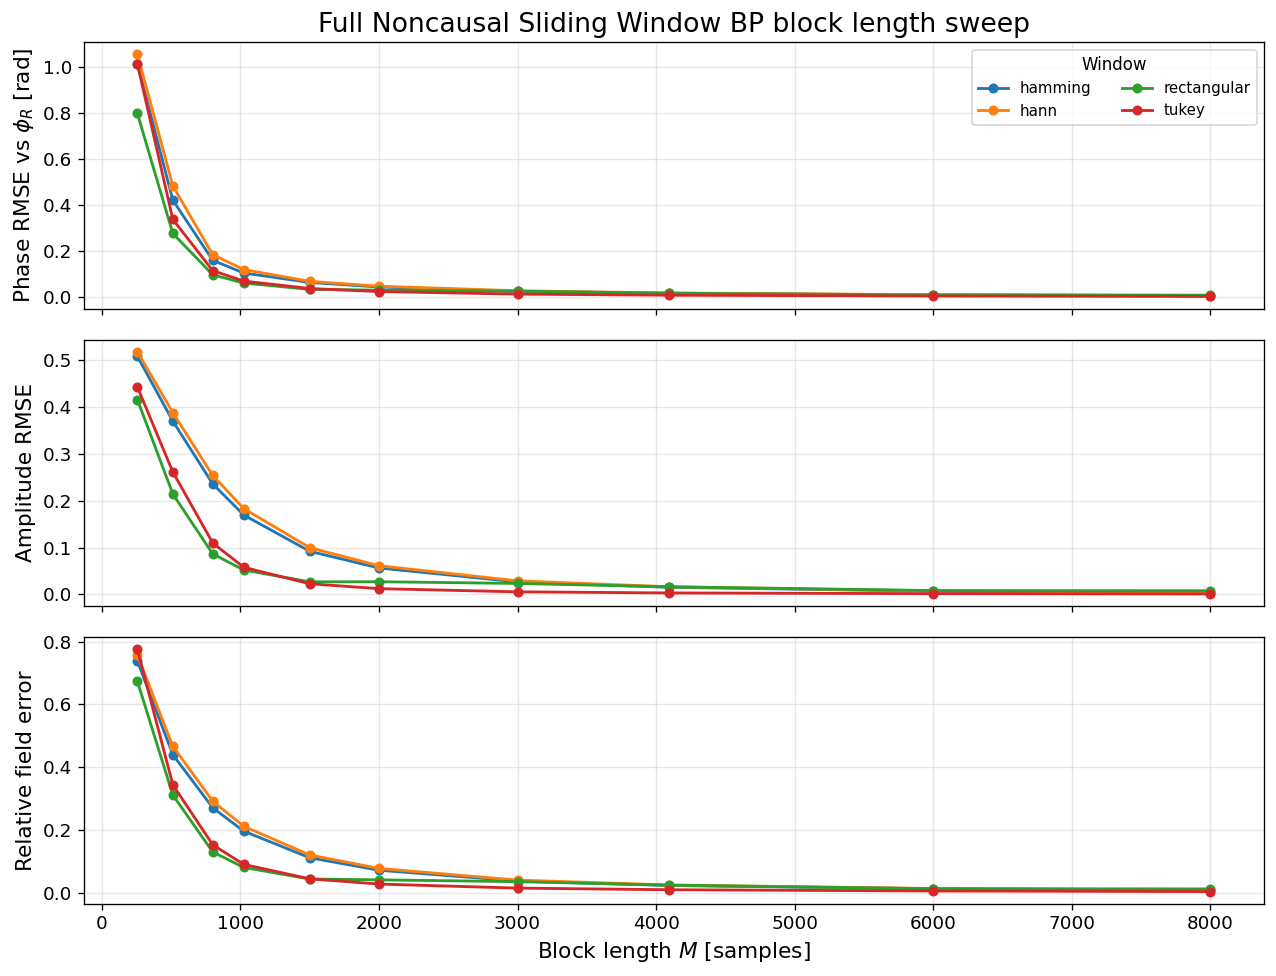

In [18]:
valid_buffer_df = buffer_df.dropna(subset=["field_rel_error", "phase_rmse_rad", "amp_rmse"])

fig, axes = plt.subplots(3, 1, figsize=(10.8, 8.3), sharex=True)
for ax, metric, ylabel in [
    (axes[0], "phase_rmse_rad", r"Phase RMSE vs $\phi_R$ [rad]"),
    (axes[1], "amp_rmse", "Amplitude RMSE"),
    (axes[2], "field_rel_error", "Relative field error"),
]:
    for window, group in valid_buffer_df.groupby("window"):
        group = group.sort_values("block_len")
        ax.plot(group["block_len"], group[metric], marker="o", label=window)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axes[0].set_title("Full Noncausal Sliding Window BP block length sweep")
axes[-1].set_xlabel("Block length $M$ [samples]")
axes[0].legend(title="Window", ncol=2)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "sliding_window_bp_with_buffer_error_summary.png", dpi=300)
plt.show()


## Real/Imaginary VAR Forecast Model

A VAR model is fitted before the evaluation interval using `[real(u_rx), imag(u_rx)]`, i.e., the real and imaginary parts of the received scintillation signal. This keeps the forecast representation aligned with the complex signal used by the sliding-window BP expression.


In [19]:
feature_series = np.column_stack([np.real(u_rx), np.imag(u_rx)])
forecast_half = forecast_block_len // 2
forecast_future_context = forecast_block_len - forecast_half - 1
forecast_eval_start = max(forecast_eval_start_requested, forecast_half)
forecast_eval_stop = min(forecast_eval_start + forecast_eval_len, N - forecast_future_context)
forecast_eval_indices = np.arange(forecast_eval_start, forecast_eval_stop)
forecast_eval_idx = np.zeros(N, dtype=bool)
forecast_eval_idx[forecast_eval_indices] = True

var_train_stop = min(var_train_stop_requested, forecast_eval_start)
var_results = VAR(feature_series[:var_train_stop]).fit(maxlags=var_lag_order, trend="c")

var_summary_df = pd.DataFrame(
    [
        {
            "name": "real_imag_var",
            "block_len": forecast_block_len,
            "window": "rectangular",
            "forecast_half_window_samples": forecast_half,
            "forecast_future_context_samples": forecast_future_context,
            "forecast_eval_start": int(forecast_eval_start),
            "forecast_eval_stop": int(forecast_eval_stop),
            "forecast_eval_len": int(len(forecast_eval_indices)),
            "var_train_stop": int(var_train_stop),
            "var_k_ar": int(var_results.k_ar),
            "var_aic": float(var_results.aic),
            "var_bic": float(var_results.bic),
            "latencies_samples": ",".join(map(str, forecast_latencies_examples)),
        }
    ]
)
var_summary_df.to_csv(output_dir / "real_imag_var_forecast_model_summary.csv", index=False)
var_summary_df


,name,block_len,window,forecast_half_window_samples,forecast_future_context_samples,forecast_eval_start,forecast_eval_stop,forecast_eval_len,var_train_stop,var_k_ar,var_aic,var_bic,latencies_samples
0,real_imag_var,1024,rectangular,512,511,4000,7000,3000,3500,4,-19.610159,-19.578446,"0,32,64"


In [20]:
def forecast_sliding_window_bp(latency_samples):
    latency_samples = int(np.clip(latency_samples, 0, forecast_future_context))
    forecast_steps = forecast_future_context - latency_samples
    H_block = backprop_kernel(forecast_block_len)
    w = window_samples(forecast_window, forecast_block_len)
    psi = np.full(N, np.nan + 1j * np.nan, dtype=complex)

    for k in forecast_eval_indices:
        start = k - forecast_half
        observed_stop = k + latency_samples
        block_stop = k + forecast_future_context
        true_prefix = u_rx[start : observed_stop + 1]

        if forecast_steps:
            history = feature_series[observed_stop + 1 - var_results.k_ar : observed_stop + 1]
            forecast_features = var_results.forecast(history, steps=forecast_steps)
            forecast_tail = forecast_features[:, 0] + 1j * forecast_features[:, 1]
            block = np.concatenate([true_prefix, forecast_tail])
        else:
            block = u_rx[start : block_stop + 1]

        psi[k] = sliding_window_bp_value(block, H_block, w, forecast_half)

    return psi

For latency zero, samples through `k` are treated as available. Samples from `k+1` through the end of the future half-window are filled by the real/imaginary VAR forecast. Sliding Window BP with VAR Forecasting is compared against the true phase-screen realization and Full Noncausal Sliding Window BP.


In [21]:
forecast_psi_by_latency = {}
forecast_rows_fine = []
forecast_rows_examples = []

psi_full_noncausal = sliding_window_bp(u_rx, forecast_block_len, forecast_window, forecast_eval_indices)
full_noncausal_metrics = compute_field_metrics(u_screen, psi_full_noncausal, forecast_eval_idx)

for latency in forecast_latencies_fine:
    psi_forecast = forecast_sliding_window_bp(latency)
    forecast_psi_by_latency[latency] = psi_forecast
    phi_R_metrics = compute_field_metrics(u_screen, psi_forecast, forecast_eval_idx)
    full_noncausal_reference_metrics = compute_field_metrics(psi_full_noncausal, psi_forecast, forecast_eval_idx)

    row = {
        "method": "Sliding Window BP with VAR Forecasting",
        "forecast_model": "real_imag_var",
        "block_len": forecast_block_len,
        "window": "rectangular",
        "var_lag_order": var_lag_order,
        "latency_samples": latency,
        "latency_s": float(latency * dt),
        "forecast_steps": int(forecast_future_context - latency),
    }
    row.update({f"phi_R_{key}": value for key, value in phi_R_metrics.items()})
    row.update({f"full_noncausal_reference_{key}": value for key, value in full_noncausal_reference_metrics.items()})
    forecast_rows_fine.append(row)

full_row_fine = {
    "method": "Full Noncausal Sliding Window BP",
    "forecast_model": "real_imag_var",
    "block_len": forecast_block_len,
    "window": "rectangular",
    "var_lag_order": np.nan,
    "latency_samples": forecast_future_context,
    "latency_s": float(forecast_future_context * dt),
    "forecast_steps": 0,
}
full_row_fine.update({f"phi_R_{key}": value for key, value in full_noncausal_metrics.items()})
full_row_fine.update({f"full_noncausal_reference_{key}": value for key, value in compute_field_metrics(psi_full_noncausal, psi_full_noncausal, forecast_eval_idx).items()})
forecast_rows_fine.append(full_row_fine)

forecast_df_fine = pd.DataFrame(forecast_rows_fine)
forecast_df_fine.to_csv(output_dir / "sliding_window_bp_with_var_forecasting_latency_sweep.csv", index=False)


for latency in forecast_latencies_examples:
    psi_forecast = forecast_sliding_window_bp(latency)
    forecast_psi_by_latency[latency] = psi_forecast
    phi_R_metrics = compute_field_metrics(u_screen, psi_forecast, forecast_eval_idx)
    full_noncausal_reference_metrics = compute_field_metrics(psi_full_noncausal, psi_forecast, forecast_eval_idx)

    row = {
        "method": "Sliding Window BP with VAR Forecasting",
        "forecast_model": "real_imag_var",
        "block_len": forecast_block_len,
        "window": "rectangular",
        "var_lag_order": var_lag_order,
        "latency_samples": latency,
        "latency_s": float(latency * dt),
        "forecast_steps": int(forecast_future_context - latency),
    }
    row.update({f"phi_R_{key}": value for key, value in phi_R_metrics.items()})
    row.update({f"full_noncausal_reference_{key}": value for key, value in full_noncausal_reference_metrics.items()})
    forecast_rows_examples.append(row)

full_row_examples = {
    "method": "Full Noncausal Sliding Window BP",
    "forecast_model": "real_imag_var",
    "block_len": forecast_block_len,
    "window": "rectangular",
    "var_lag_order": np.nan,
    "latency_samples": forecast_future_context,
    "latency_s": float(forecast_future_context * dt),
    "forecast_steps": 0,
}
full_row_examples.update({f"phi_R_{key}": value for key, value in full_noncausal_metrics.items()})
full_row_examples.update({f"full_noncausal_reference_{key}": value for key, value in compute_field_metrics(psi_full_noncausal, psi_full_noncausal, forecast_eval_idx).items()})
forecast_rows_examples.append(full_row_examples)

forecast_df_examples = pd.DataFrame(forecast_rows_examples)
forecast_df_examples.to_csv(output_dir / "sliding_window_bp_with_var_forecasting_latency_sweep.csv", index=False)

In [22]:
best_forecast_row = forecast_df_fine[forecast_df_fine["method"].eq("Sliding Window BP with VAR Forecasting")].sort_values(
    "phi_R_phase_rmse_rad"
).iloc[0]
best_latency_samples = int(best_forecast_row["latency_samples"])
best_forecast_row


method                                        Sliding Window BP with VAR Forecasting
forecast_model                                                         real_imag_var
block_len                                                                       1024
window                                                                   rectangular
var_lag_order                                                                    4.0
latency_samples                                                                  456
latency_s                                                                       4.56
forecast_steps                                                                    55
phi_R_num_valid_samples                                                         3000
phi_R_field_rel_error                                                       0.077859
phi_R_amp_rmse                                                              0.053571
phi_R_phase_rmse_rad                                             

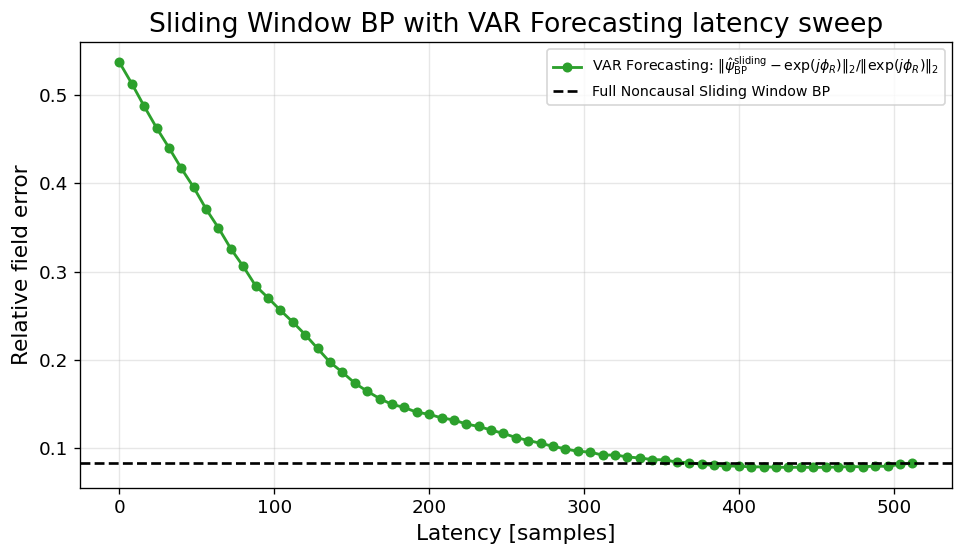

In [23]:
plot_stop = min(plot_start + n_plot, forecast_eval_stop)
sl = slice(plot_start, plot_stop)
samples = np.arange(plot_start, plot_stop)
plot_idx = np.zeros(N, dtype=bool)
plot_idx[sl] = True
phase_true_refractive = phi_R.copy()
phase_full_noncausal = unwrap_finite_phase(psi_full_noncausal)
phase_full_noncausal_aligned = median_align_to_reference(phase_full_noncausal, phase_true_refractive, plot_idx)

latency_plot_df = forecast_df_fine[forecast_df_fine["method"].eq("Sliding Window BP with VAR Forecasting")].sort_values(
    "latency_samples"
)
latency_values = [int(x) for x in latency_plot_df["latency_samples"]]
latency_colors = dict(zip(latency_values, plt.cm.viridis(np.linspace(0.08, 0.88, len(latency_values)))))

full_noncausal_row = forecast_df_fine[forecast_df_fine["method"].eq("Full Noncausal Sliding Window BP")].iloc[0]

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.plot(
    latency_plot_df["latency_samples"],
    latency_plot_df["phi_R_field_rel_error"],
    marker="o",
    color="tab:green",
    label=r"VAR Forecasting: $\|\hat{\psi}_{\mathrm{BP}}^{\mathrm{sliding}}-\exp(j\phi_R)\|_2/\|\exp(j\phi_R)\|_2$",
)
ax.axhline(
    full_noncausal_row["phi_R_field_rel_error"],
    color="k",
    linestyle="--",
    linewidth=1.6,
    label="Full Noncausal Sliding Window BP",
)
ax.set_title("Sliding Window BP with VAR Forecasting latency sweep")
ax.set_xlabel("Latency [samples]")
ax.set_ylabel("Relative field error")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8.5)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "sliding_window_bp_latency_error_overlay.png", dpi=300)
plt.show()


## Forecast Example for the Received Complex Signal

This plot shows the latency-dependent VAR forecast of the missing future received scintillation samples for one time index. The observed side is what would be available in real time; the real/imaginary VAR forecast is compared directly with the true future received signal real and imaginary parts.


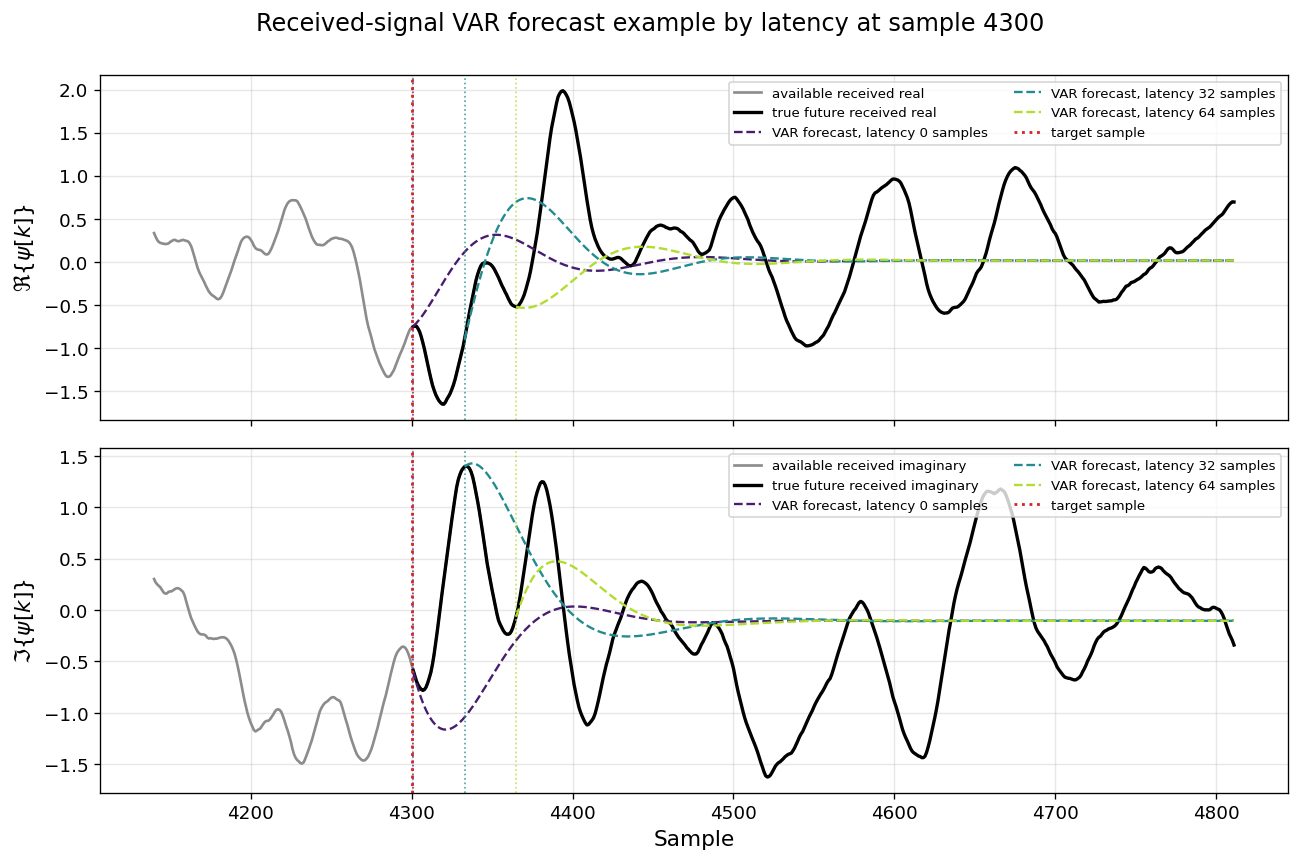

In [24]:
latency_plot_df = forecast_df_examples[forecast_df_examples["method"].eq("Sliding Window BP with VAR Forecasting")].sort_values(
    "latency_samples"
)
latency_values = [int(x) for x in latency_plot_df["latency_samples"]]
latency_colors = dict(zip(latency_values, plt.cm.viridis(np.linspace(0.08, 0.88, len(latency_values)))))

def forecast_future_example(latency_samples):
    latency_samples = int(np.clip(latency_samples, 0, forecast_future_context))
    observed_stop = forecast_example_index + latency_samples
    forecast_steps = forecast_future_context - latency_samples
    true_future_start = observed_stop + 1
    true_future_stop = forecast_example_index + forecast_future_context + 1
    history = feature_series[observed_stop + 1 - var_results.k_ar : observed_stop + 1]
    forecast_features = var_results.forecast(history, steps=forecast_steps)
    forecast_tail = forecast_features[:, 0] + 1j * forecast_features[:, 1]
    true_tail = u_rx[true_future_start:true_future_stop]
    return np.arange(true_future_start, true_future_stop), true_tail, forecast_tail

max_example_steps = forecast_future_context
true_future_axis = np.arange(forecast_example_index + 1, forecast_example_index + max_example_steps + 1)
true_future = u_rx[forecast_example_index + 1 : forecast_example_index + max_example_steps + 1]

example_forecasts = {latency: forecast_future_example(latency) for latency in latency_values}
max_latency = max(latency_values)
context_start = max(forecast_example_index - forecast_example_context_samples, 0)
context_stop = min(forecast_example_index + max_latency + 1, N)
context_axis = np.arange(context_start, context_stop)
context_values = u_rx[context_start:context_stop]

forecast_example_df = pd.DataFrame(
    {
        "sample": true_future_axis,
        "true_real": np.real(true_future),
        "true_imag": np.imag(true_future),
    }
)
for latency, (future_axis, true_tail, forecast_tail) in example_forecasts.items():
    real_col = np.full(len(true_future_axis), np.nan)
    imag_col = np.full(len(true_future_axis), np.nan)
    start = int(future_axis[0] - true_future_axis[0]) if len(future_axis) else 0
    stop = min(start + len(forecast_tail), len(true_future_axis))
    if stop > start:
        real_col[start:stop] = np.real(forecast_tail[: stop - start])
        imag_col[start:stop] = np.imag(forecast_tail[: stop - start])
    forecast_example_df[f"real_imag_var_latency_{latency}_forecast_real"] = real_col
    forecast_example_df[f"real_imag_var_latency_{latency}_forecast_imag"] = imag_col
forecast_example_df.to_csv(output_dir / "real_imag_var_forecast_example_complex_parts.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(11.0, 7.2), sharex=True)
axes[0].plot(context_axis, np.real(context_values), color="0.55", linewidth=1.6, label="available received real")
axes[0].plot(true_future_axis, np.real(true_future), color="k", linewidth=2, label="true future received real")
axes[1].plot(context_axis, np.imag(context_values), color="0.55", linewidth=1.6, label="available received imaginary")
axes[1].plot(true_future_axis, np.imag(true_future), color="k", linewidth=2, label="true future received imaginary")

for latency, (future_axis, true_tail, forecast_tail) in example_forecasts.items():
    color = latency_colors[latency]
    forecast_start = forecast_example_index + latency + 1
    axes[0].plot(future_axis, np.real(forecast_tail), "--", color=color, linewidth=1.4, label=f"VAR forecast, latency {latency} samples")
    axes[1].plot(future_axis, np.imag(forecast_tail), "--", color=color, linewidth=1.4, label=f"VAR forecast, latency {latency} samples")
    axes[0].axvline(forecast_start, color=color, linestyle=":", linewidth=1.0, alpha=0.8)
    axes[1].axvline(forecast_start, color=color, linestyle=":", linewidth=1.0, alpha=0.8)

axes[0].axvline(forecast_example_index, color="tab:red", linestyle=":", label="target sample")
axes[1].axvline(forecast_example_index, color="tab:red", linestyle=":", label="target sample")
axes[0].set_ylabel(r"$\Re\{\psi[k]\}$")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel(r"$\Im\{\psi[k]\}$")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, fontsize=8)
fig.suptitle(f"Received-signal VAR forecast example by latency at sample {forecast_example_index}", y=0.995)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "real_imag_var_forecast_example_complex_parts.png", dpi=300)
plt.show()


The phase traces below compare the propagated field phase, Full Noncausal Sliding Window BP, and Sliding Window BP with VAR Forecasting against the true phase-screen realization `phi_R`. The backpropagated phases have a constant phase offset removed before plotting.


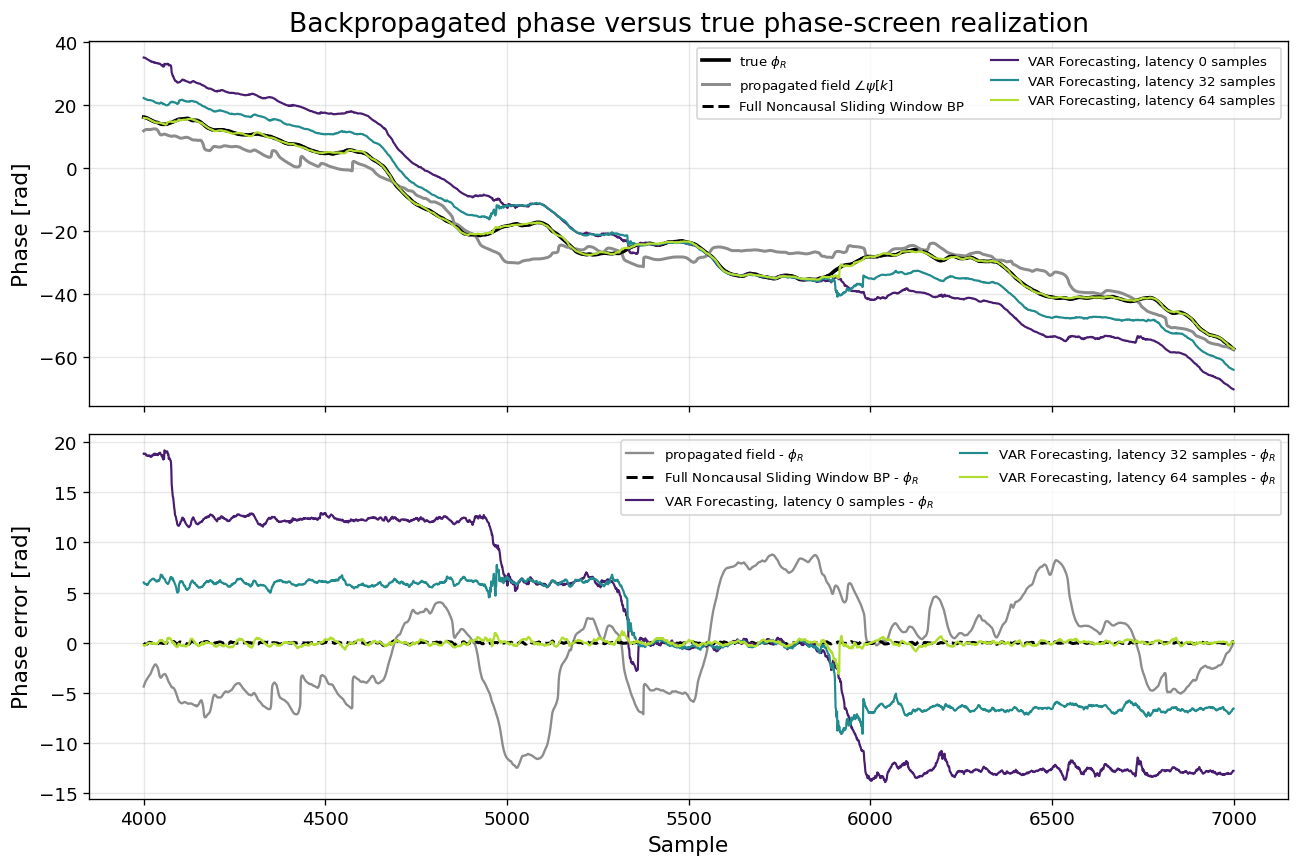

In [25]:
phase_propagated = phase_rx.copy()
phase_propagated_aligned = median_align_to_reference(phase_propagated, phase_true_refractive, plot_idx)

fig, axes = plt.subplots(2, 1, figsize=(11.0, 7.4), sharex=True)
axes[0].plot(samples, phase_true_refractive[sl], "k", linewidth=2.2, label=r"true $\phi_R$")
axes[0].plot(samples, phase_propagated_aligned[sl], color="0.55", linewidth=1.8, label=r"propagated field $\angle\psi[k]$")
axes[0].plot(samples, phase_full_noncausal_aligned[sl], "k--", linewidth=1.8, label="Full Noncausal Sliding Window BP")

axes[1].plot(samples, phase_propagated_aligned[sl] - phase_true_refractive[sl], color="0.55", linewidth=1.4, label=r"propagated field - $\phi_R$")
axes[1].plot(samples, phase_full_noncausal_aligned[sl] - phase_true_refractive[sl], "k--", linewidth=1.8, label=r"Full Noncausal Sliding Window BP - $\phi_R$")

for latency in latency_values:
    color = latency_colors[latency]
    phase_latency = unwrap_finite_phase(forecast_psi_by_latency[latency])
    phase_latency_aligned = median_align_to_reference(phase_latency, phase_true_refractive, plot_idx)
    axes[0].plot(samples, phase_latency_aligned[sl], color=color, linewidth=1.3, label=f"VAR Forecasting, latency {latency} samples")
    axes[1].plot(samples, phase_latency_aligned[sl] - phase_true_refractive[sl], color=color, linewidth=1.3, label=rf"VAR Forecasting, latency {latency} samples - $\phi_R$")

axes[0].set_ylabel("Phase [rad]")
axes[0].set_title("Backpropagated phase versus true phase-screen realization")
axes[0].grid(True, alpha=0.3)
axes[0].legend(ncol=2, fontsize=8)
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Phase error [rad]")
axes[1].grid(True, alpha=0.3)
axes[1].legend(ncol=2, fontsize=8)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "phase_sliding_window_bp_var_forecasting_true_phi_R.png", dpi=300)
plt.show()


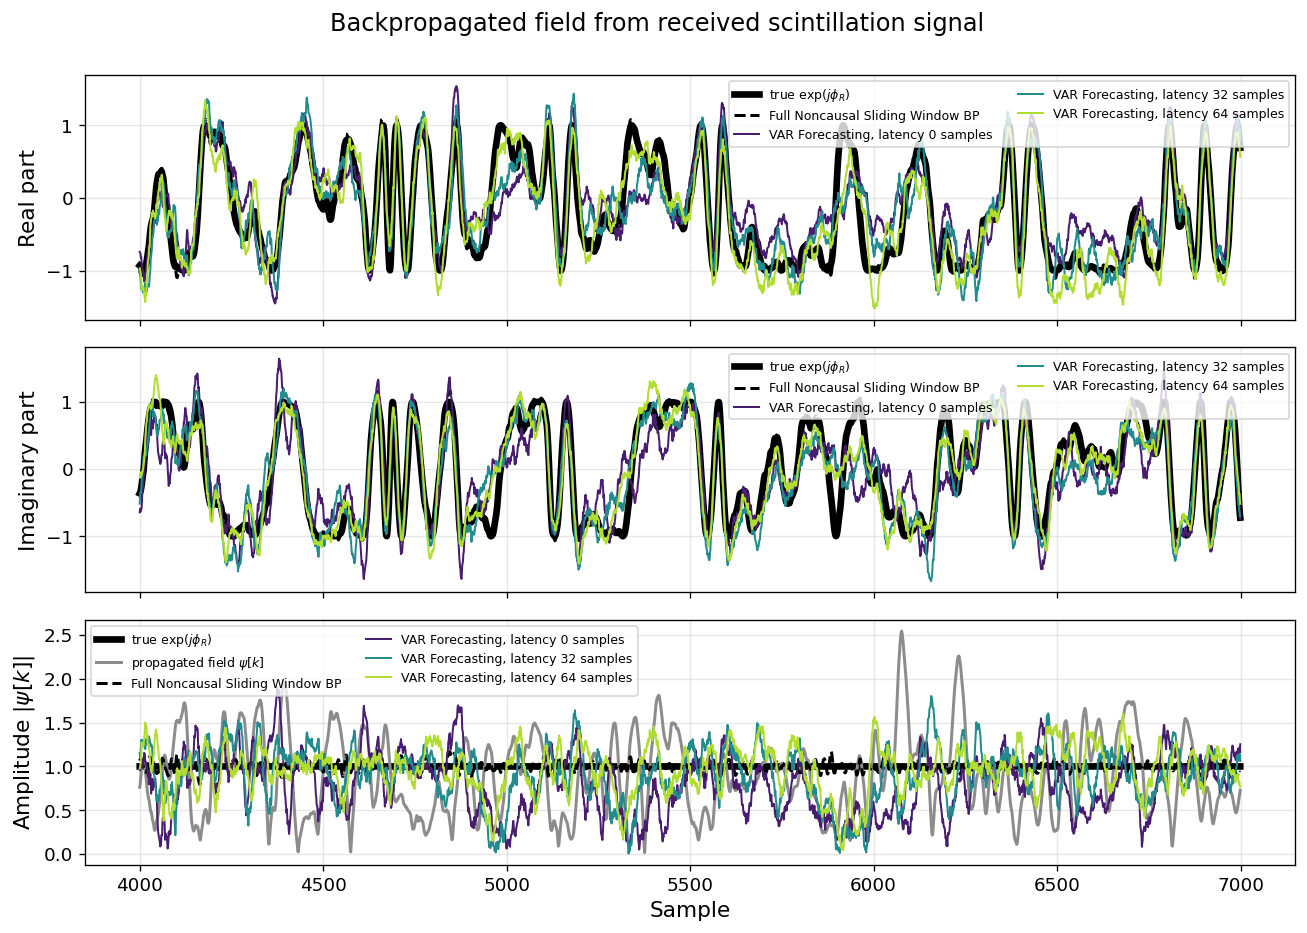

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(11.0, 7.8), sharex=True)
axes[0].plot(samples, np.real(u_screen[sl]), "k", linewidth=4, label=r"true $\exp(j\phi_R)$")
axes[0].plot(samples, np.real(psi_full_noncausal[sl]), "k--", linewidth=1.8, label="Full Noncausal Sliding Window BP")
axes[1].plot(samples, np.imag(u_screen[sl]), "k", linewidth=4, label=r"true $\exp(j\phi_R)$")
axes[1].plot(samples, np.imag(psi_full_noncausal[sl]), "k--", linewidth=1.8, label="Full Noncausal Sliding Window BP")
axes[2].plot(samples, np.abs(u_screen[sl]), "k", linewidth=4, label=r"true $\exp(j\phi_R)$")
axes[2].plot(samples, np.abs(u_rx[sl]), color="0.55", linewidth=1.8, label=r"propagated field $\psi[k]$")
axes[2].plot(samples, np.abs(psi_full_noncausal[sl]), "k--", linewidth=1.8, label="Full Noncausal Sliding Window BP")

for latency in latency_values:
    color = latency_colors[latency]
    psi_latency = forecast_psi_by_latency[latency]
    label = f"VAR Forecasting, latency {latency} samples"
    axes[0].plot(samples, np.real(psi_latency[sl]), color=color, linewidth=1.2, label=label)
    axes[1].plot(samples, np.imag(psi_latency[sl]), color=color, linewidth=1.2, label=label)
    axes[2].plot(samples, np.abs(psi_latency[sl]), color=color, linewidth=1.2, label=label)

axes[0].set_ylabel("Real part")
axes[1].set_ylabel("Imaginary part")
axes[2].set_ylabel(r"Amplitude $|\psi[k]|$")
axes[2].set_xlabel("Sample")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2, fontsize=7.5)
fig.suptitle("Backpropagated field from received scintillation signal", y=0.995)
fig.tight_layout(pad=1.1)
fig.savefig(output_dir / "backpropagated_field_sliding_window_bp_var_forecasting.png", dpi=300)
plt.show()


## Notes

The full-record inverse FFT is only a sanity check: because it applies the exact inverse kernel to the simulated received signal, it should recover `exp(j phi_R)` up to numerical precision and phase unwrapping. Full Noncausal Sliding Window BP shows the finite-window approximation when true future samples are available.

The zero-latency forecast comparison uses a VAR fitted directly to the real and imaginary parts of the received scintillation signal. The phase plots compare against the true phase-screen realization `phi_R` and include the propagated field phase `unwrap(angle(u_rx))`.
